# Probar criterios de priorización

Cada criterio tiene su propia celda. En cada una, cambiá `USE_...` para incluir o ignorar esa regla en la priorización experimental. La tabla muestra los valores usados, qué decisión produce y la categoría acumulada hasta esa celda.

Ejecutá la notebook de arriba hacia abajo después de cambiar un interruptor. El bloque final llama a `evaluate_priority` sin interruptores y muestra la implementación vigente como comparación. Esta notebook no consulta fuentes ni genera gráficos.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from target_selection.prioritization import (
    PriorityConfig, build_priority_evidence, classify_event_stage, evaluate_priority,
    _as_hjd, _epoch_hjd, _coalesced_numeric, _coalesced_text,
    criterion_ended_event, criterion_supported_event, criterion_post_baseline,
    criterion_casleo_continuity, criterion_casleo_stale_photometry,
    criterion_casleo_missing_uncertainty, criterion_casleo_observing_question,
    criterion_casleo_no_added_information, criterion_rising_event,
    criterion_peak_event, criterion_stale_photometry, criterion_declining_event,
    criterion_unknown_event_stage, criterion_fallback,
)

RUN_DIR = Path('/tmp/seasonal_observing_plan_output')  # Set this to another completed run if needed.
AS_OF = '2026-10-16'
PRIORITY_CONFIG = PriorityConfig(
    rise_significance_sigma=3.0,  # Minimum slope significance for a rising event.
    minimum_rise_points=3,  # Minimum distinct measurements used for the rise fit.
    rise_lookback_days=90,  # Age limit for measurements used in the rise fit.
    stale_cadence_factor=2.0,  # Stale-data gap as a multiple of median survey cadence.
    stale_minimum_days=30,  # Minimum gap before external photometry is called stale.
    planned_visit_interval_days=7,  # Interval used to predict measurable event change.
    peak_half_width_t_e=0.3,  # Half-width of peak phase in units of tE.
    event_half_width_t_e=2.0,  # Event window boundary in units of tE.
    magnitude_limits=(("HSH", 16.5), ("JS", 18.0)),
)

targets = pd.read_csv(RUN_DIR / 'targets_loaded.csv', low_memory=False)
observations = pd.read_csv(RUN_DIR / 'observations.csv.gz', low_memory=False)
visibility = pd.read_csv(RUN_DIR / 'visibility' / 'visibility_summary.csv')
evidence = build_priority_evidence(
    targets, observations, visibility, as_of=AS_OF, config=PRIORITY_CONFIG,
)
evidence = evidence.reset_index(drop=True)
experiment = evidence[['target_id']].copy()
experiment['priority_category'] = pd.Series(pd.NA, index=experiment.index, dtype='object')
experiment['priority_reason'] = pd.Series(pd.NA, index=experiment.index, dtype='object')
print(f'{len(evidence):,} targets; {int(evidence.n_photometry.eq(0).sum()):,} have no usable photometry (the current implementation omits those).')

def show_criterion(name, enabled, decisions, value_columns):
    outcomes = pd.DataFrame(
        [(decision[0], decision[1]) if decision is not None else ('', '') for decision in decisions],
        columns=['criterion_category', 'criterion_reason'], index=evidence.index,
    )
    eligible = evidence['n_photometry'].gt(0)
    applies = outcomes['criterion_category'].ne('') & eligible
    first_match = experiment['priority_category'].isna()
    applied = applies & first_match if enabled else pd.Series(False, index=evidence.index)
    experiment.loc[applied, 'priority_category'] = outcomes.loc[applied, 'criterion_category']
    experiment.loc[applied, 'priority_reason'] = outcomes.loc[applied, 'criterion_reason']
    view = evidence[['target_id', *[column for column in value_columns if column in evidence]]].copy()
    view['eligible_for_priority'] = eligible
    view['criterion_applies'] = applies
    view['criterion_category'] = outcomes['criterion_category'].replace('', pd.NA)
    view['criterion_reason'] = outcomes['criterion_reason'].replace('', pd.NA)
    view['included_by_this_cell'] = applied
    view['category_after_this_cell'] = experiment['priority_category']
    print(f'{name}: enabled={enabled}; matches={int(applies.sum())}; newly assigned={int(applied.sum())}')
    display(view)


37 targets; 0 have no usable photometry (the current implementation omits those).


## Diagnóstico por target: etapa del evento

Esta celda evalúa `classify_event_stage` para cada target y muestra la decisión junto a su curva. La función calcula `τ = (fecha de evaluación − t0) / tE` y usa los límites configurados abajo. **La clasificación actual usa `t0`, `tE` y `AS_OF`; no usa puntos fotométricos.** Las curvas se incluyen al lado para contrastar esa etapa con los datos disponibles; todos los puntos con época y magnitud válidas se dibujan.


,target_id,t0_hjd,tE_days,tau,stage_from_function,stage_in_evidence,agrees_with_evidence
0,Gaia23cnu,NaN,NaN,NaN,unknown,unknown,True
1,2024-BLG-0516,2.460434e+06,1.21490,7.368106e+02,post-baseline,post-baseline,True
2,ASASSN-24fs,2.460558e+06,3.81760,2.020234e+02,post-baseline,post-baseline,True
3,OGLE-2026-BLG-0345,2.461153e+06,21.01900,8.415053e+00,post-baseline,post-baseline,True
4,OGLE-2024-BLG-0808,2.460630e+06,408.70429,1.712020e+00,decline,decline,True
5,OGLE-2023-BLG-1273,1.876680e+00,1.64371,1.497422e+06,post-baseline,post-baseline,True
6,OGLE-2026-BLG-0244,2.461119e+06,90.48200,2.325789e+00,post-baseline,post-baseline,True
7,OGLE-2026-BLG-0363,2.461217e+06,98.94400,1.137876e+00,decline,decline,True
8,OGLE-2026-BLG-0419,2.461303e+06,77.30000,3.371539e-01,decline,decline,True
9,ZTF26abyljks,NaN,NaN,NaN,unknown,unknown,True


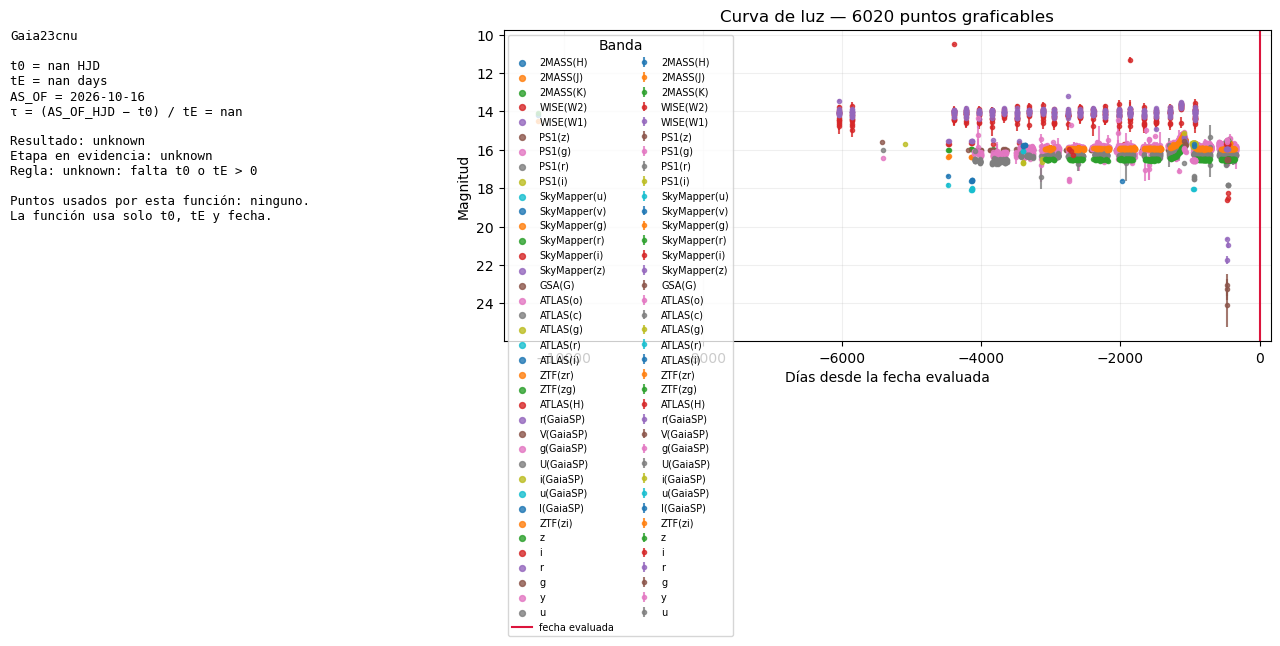

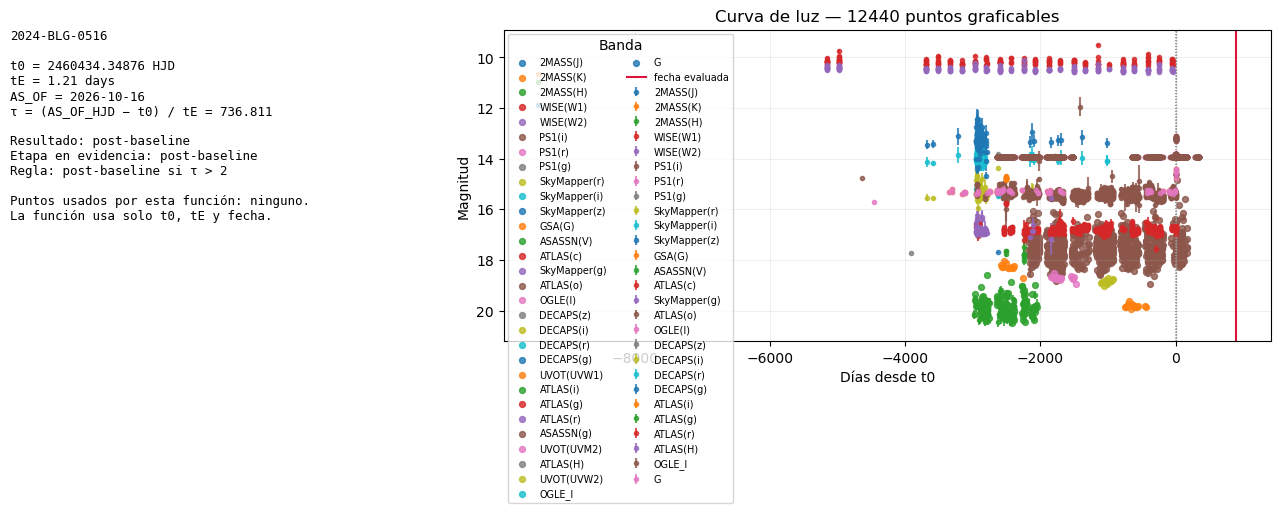

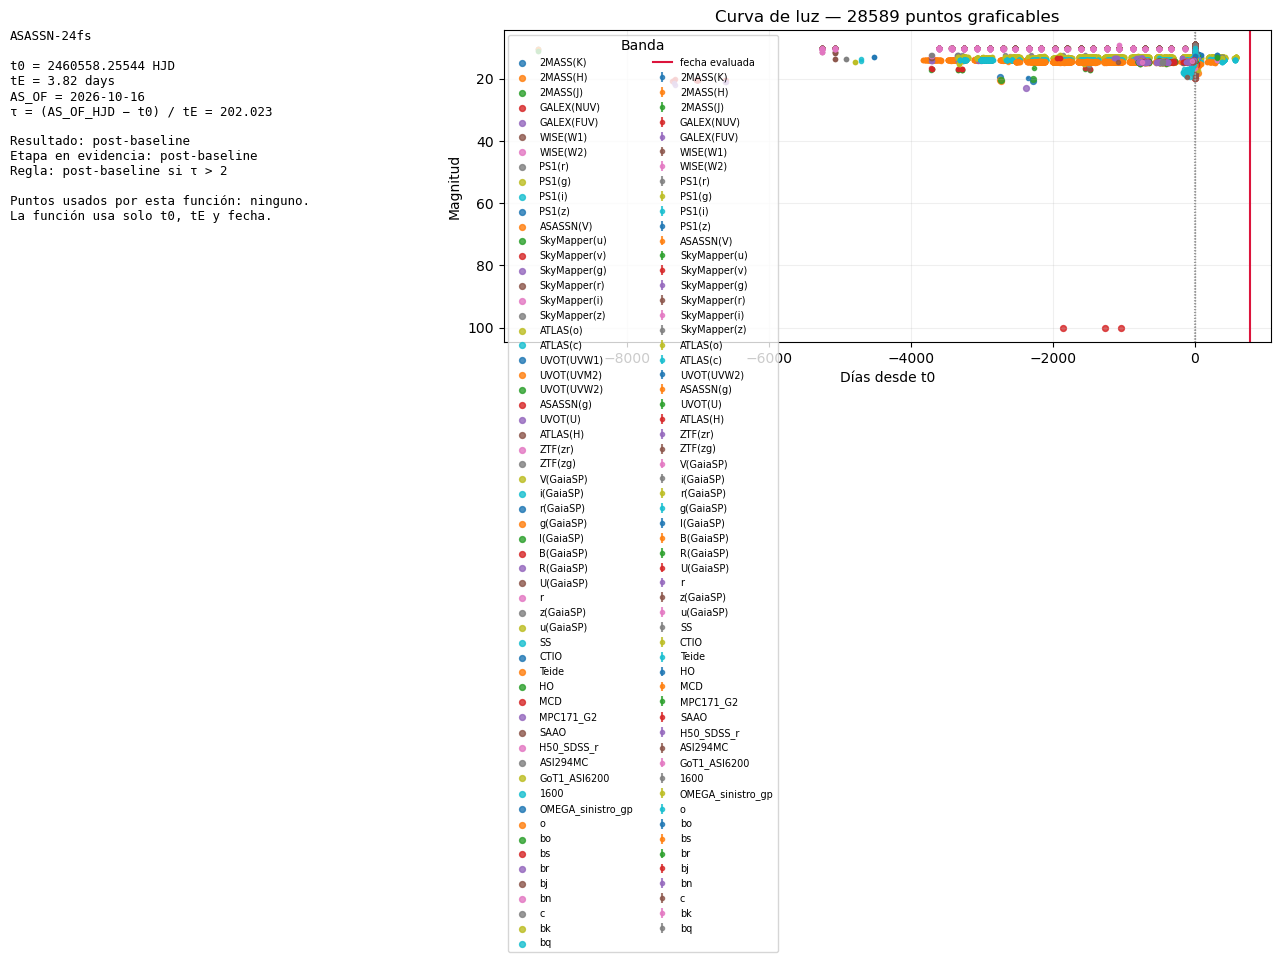

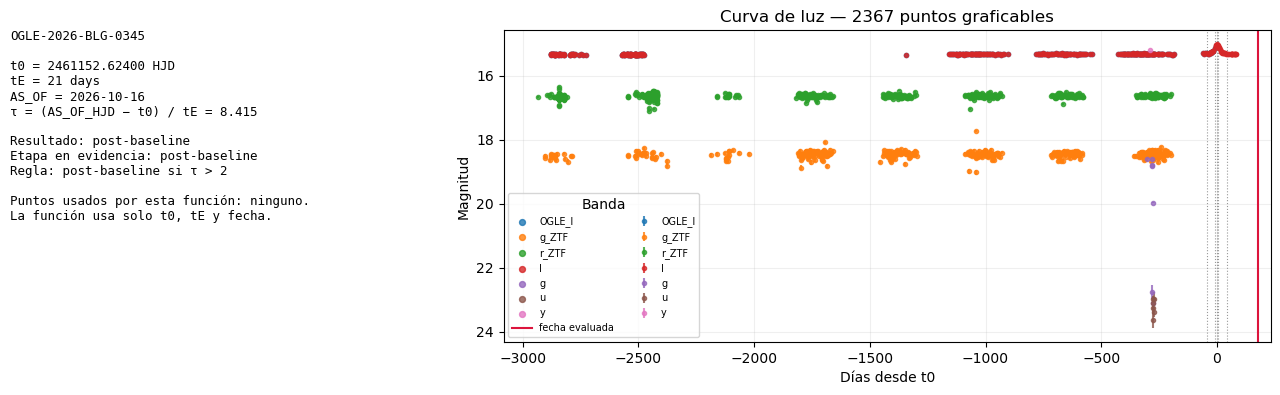

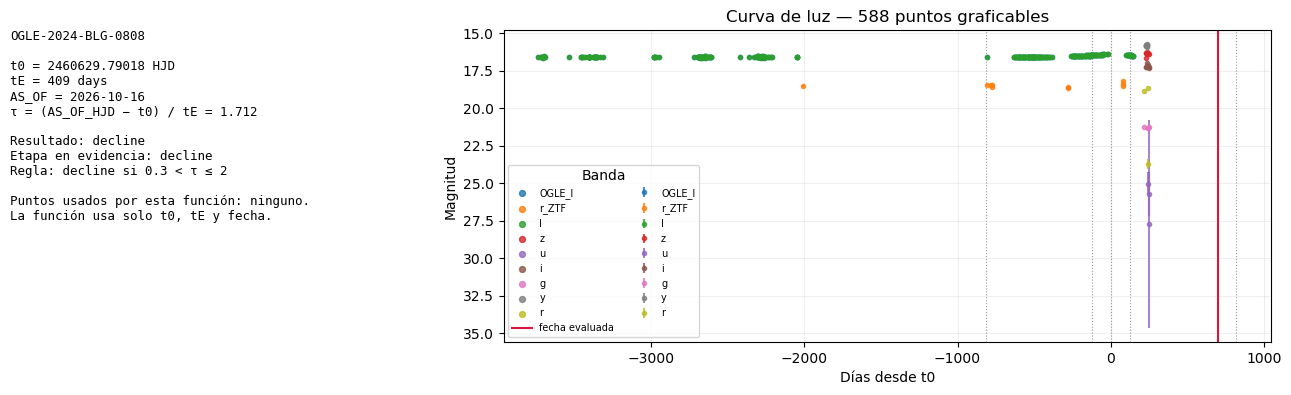

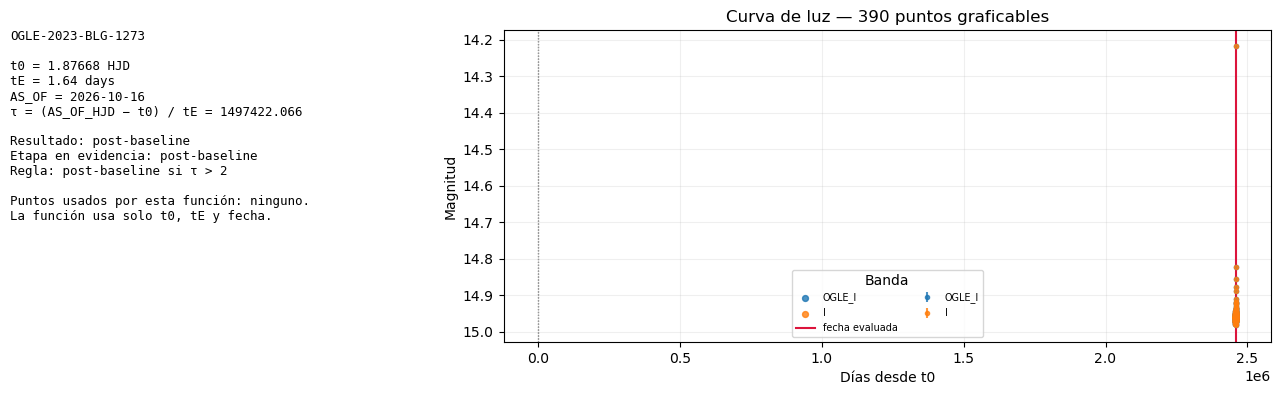

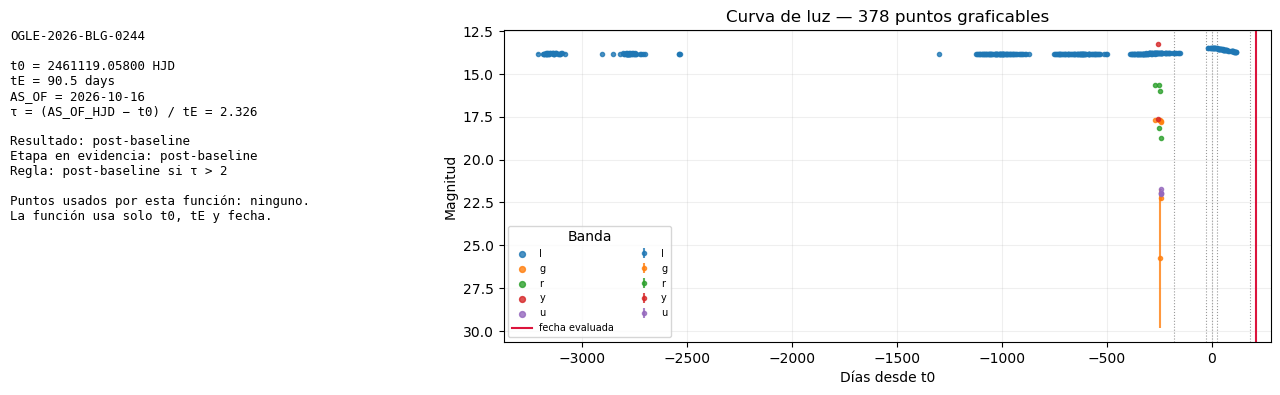

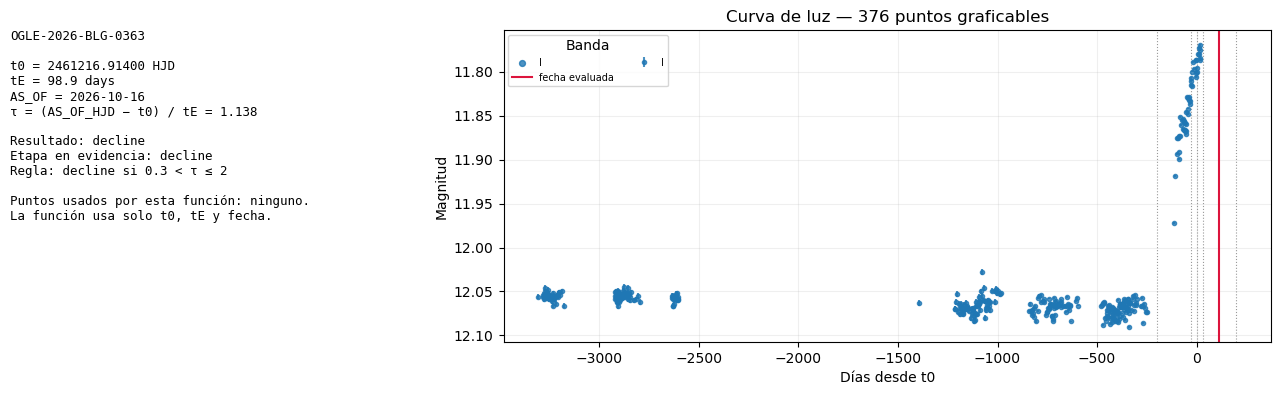

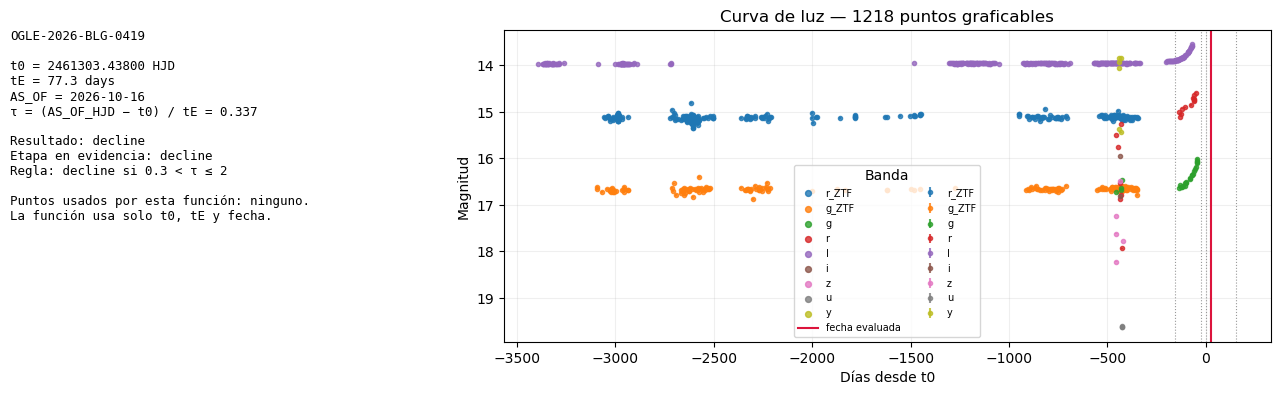

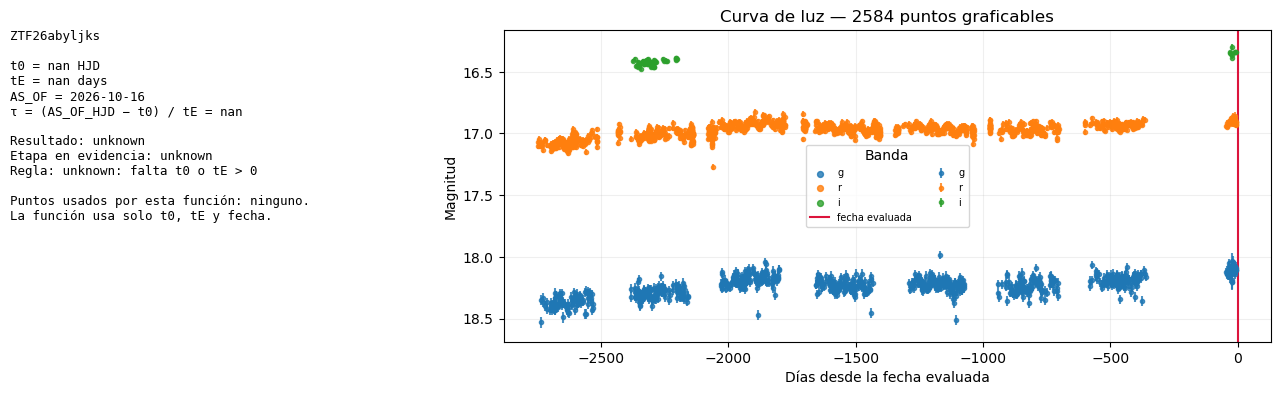

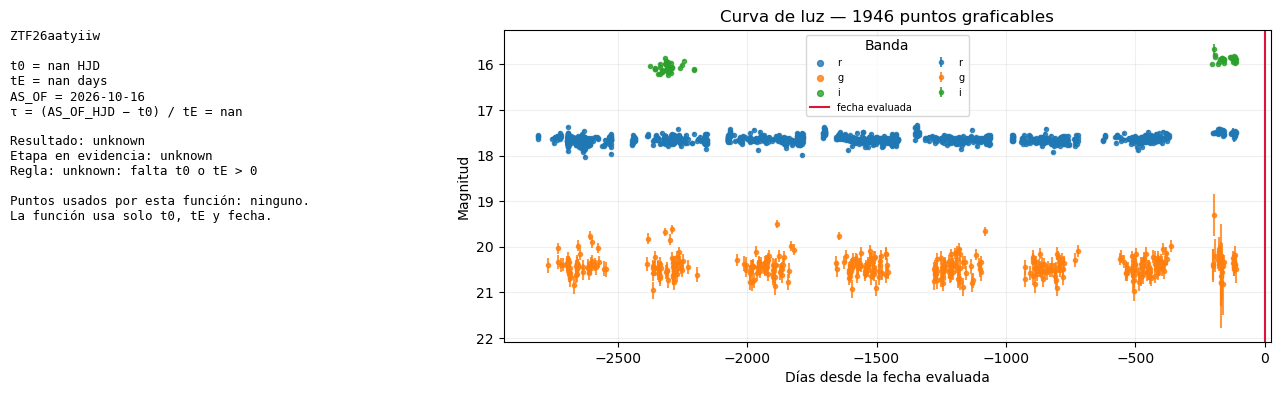

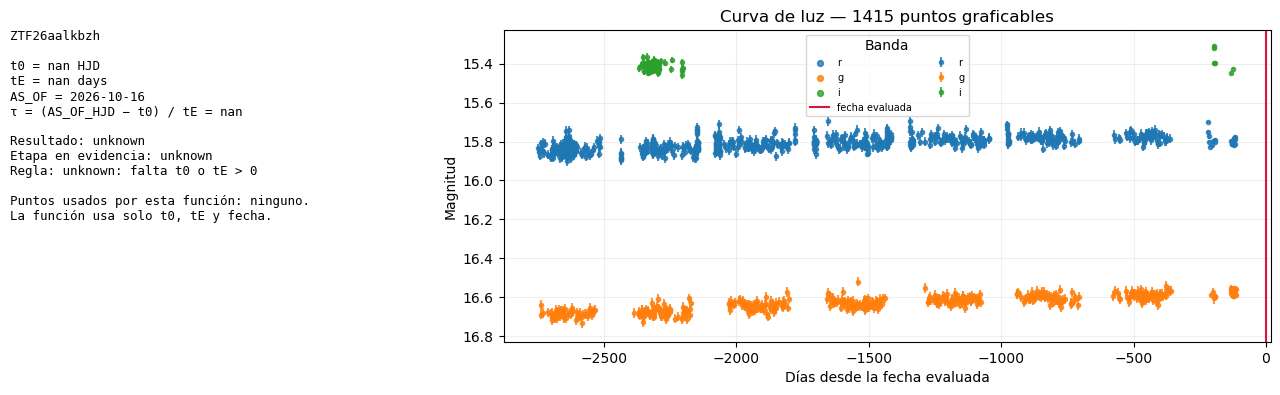

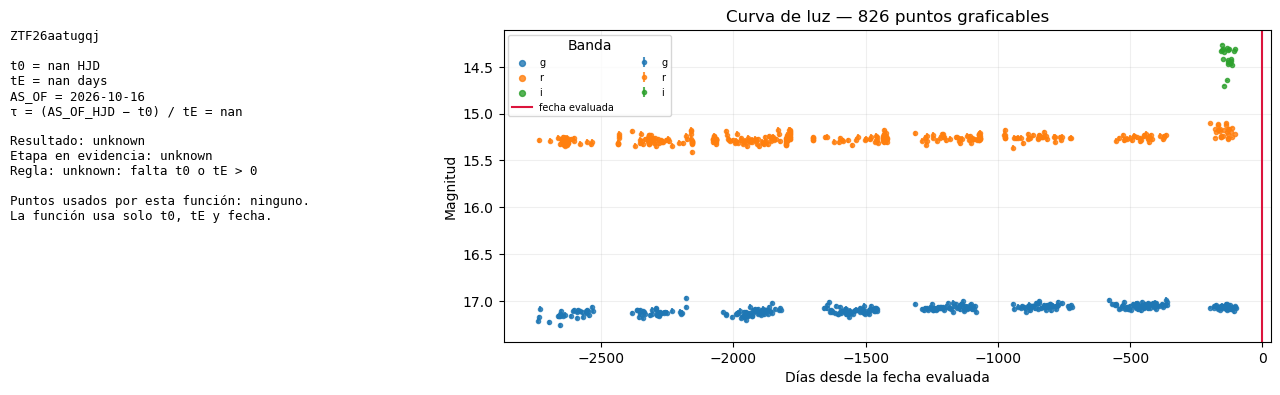

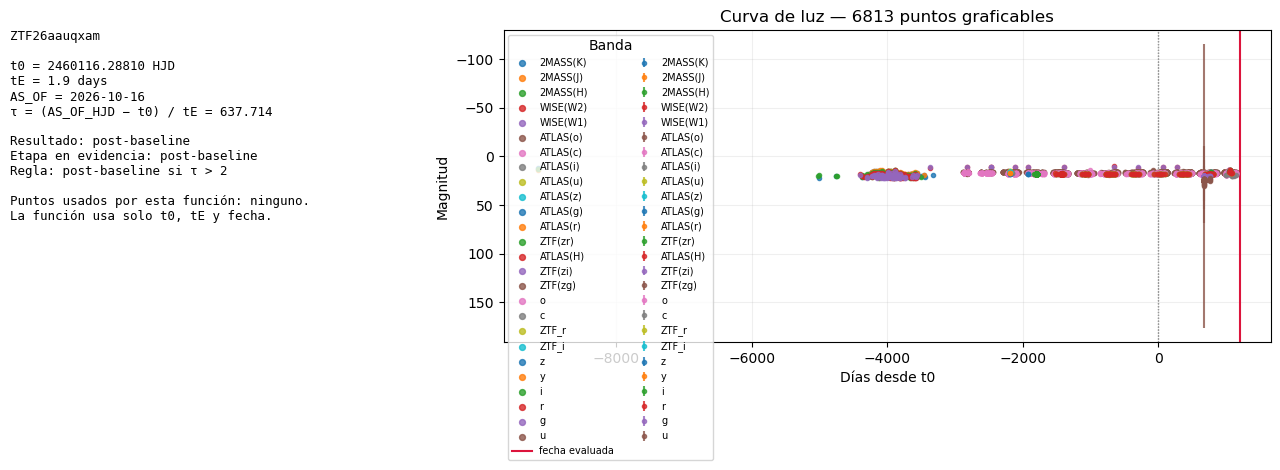

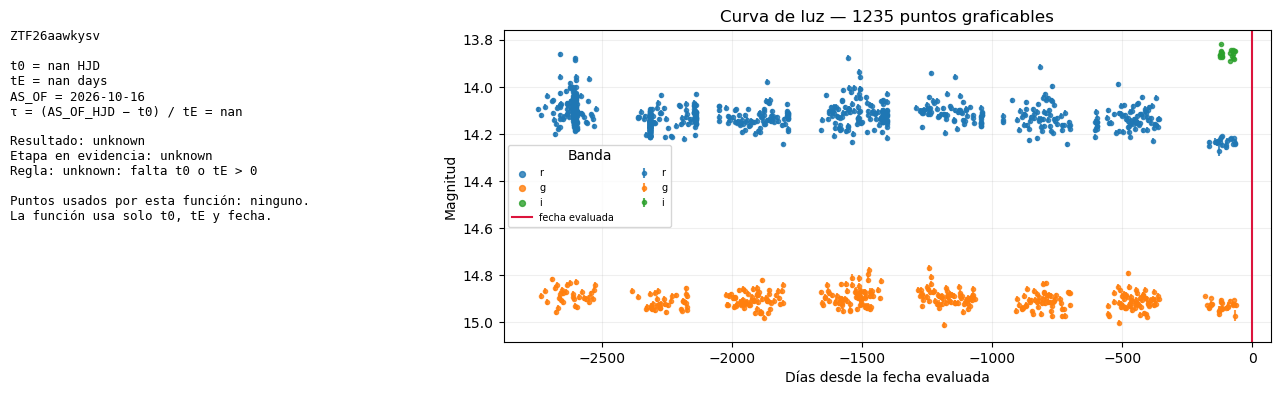

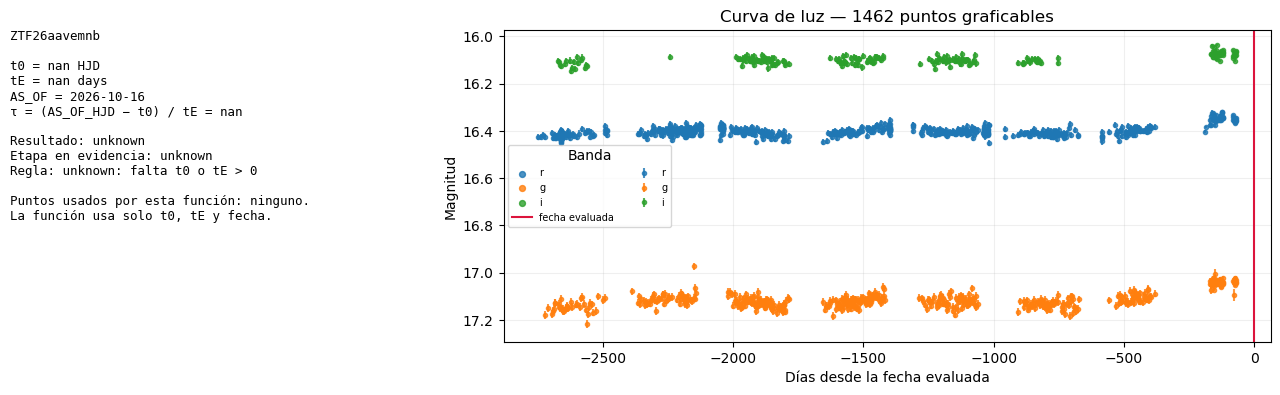

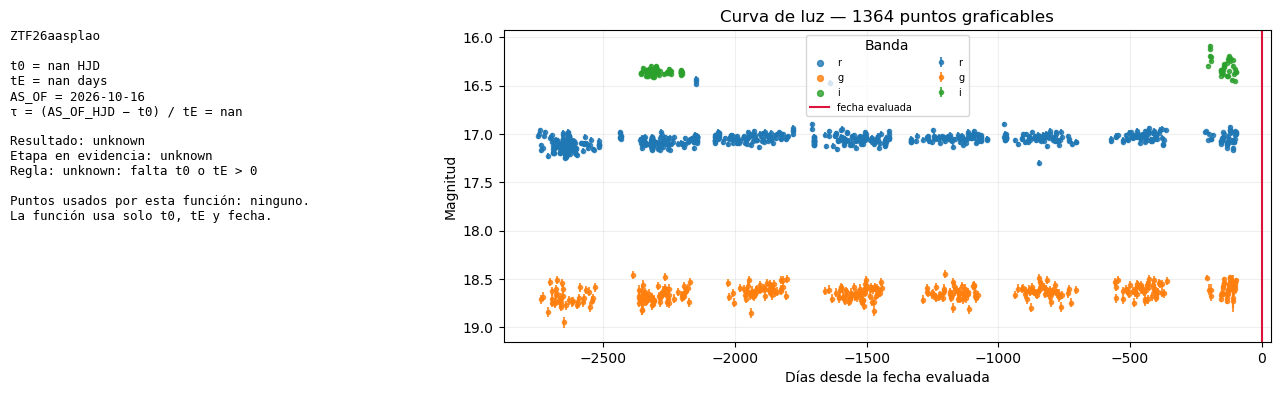

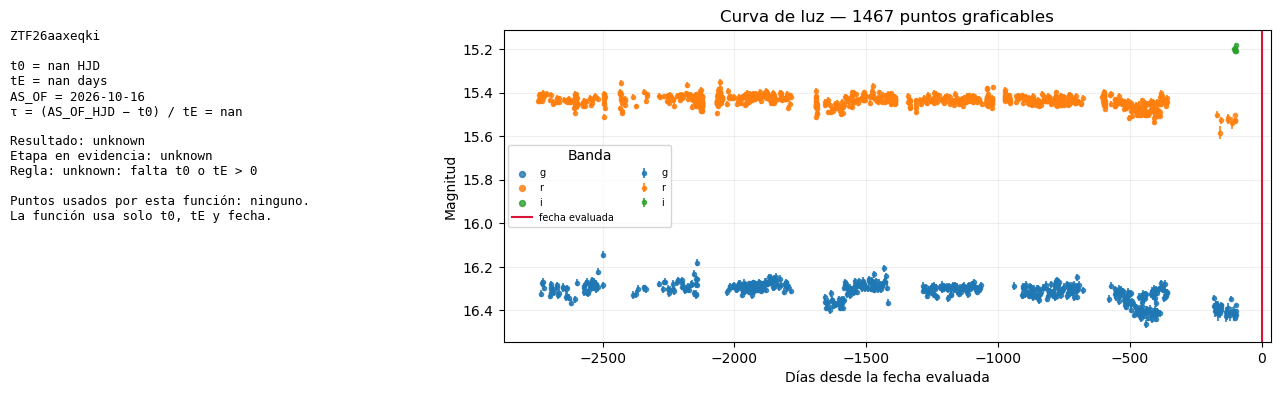

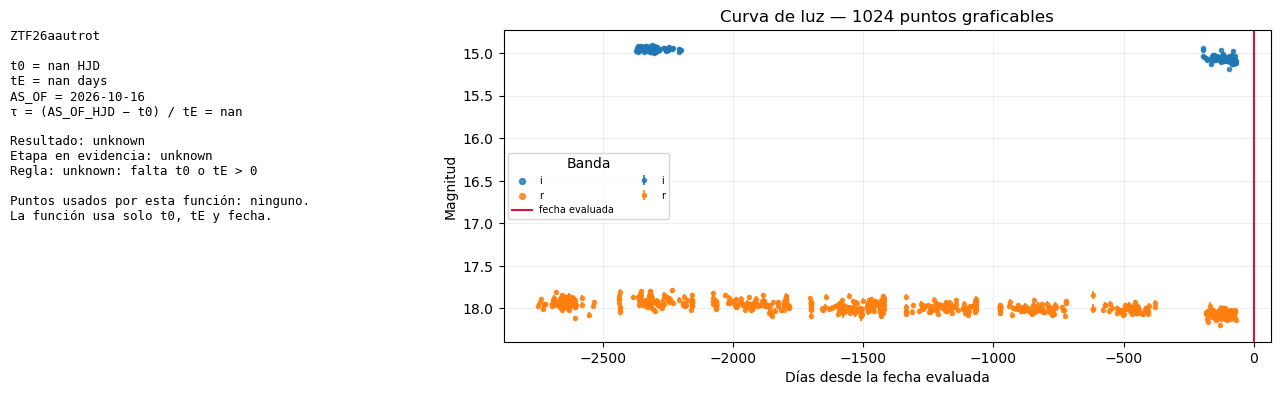

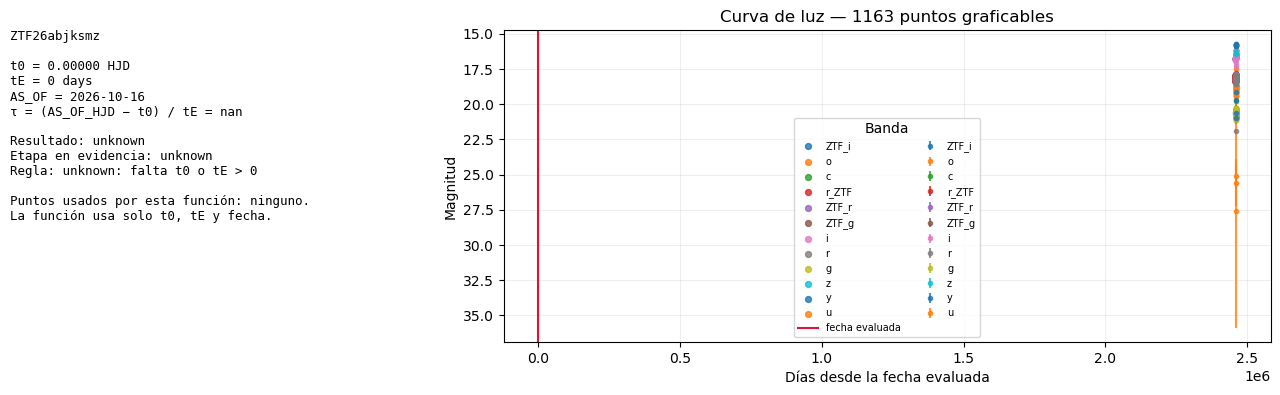

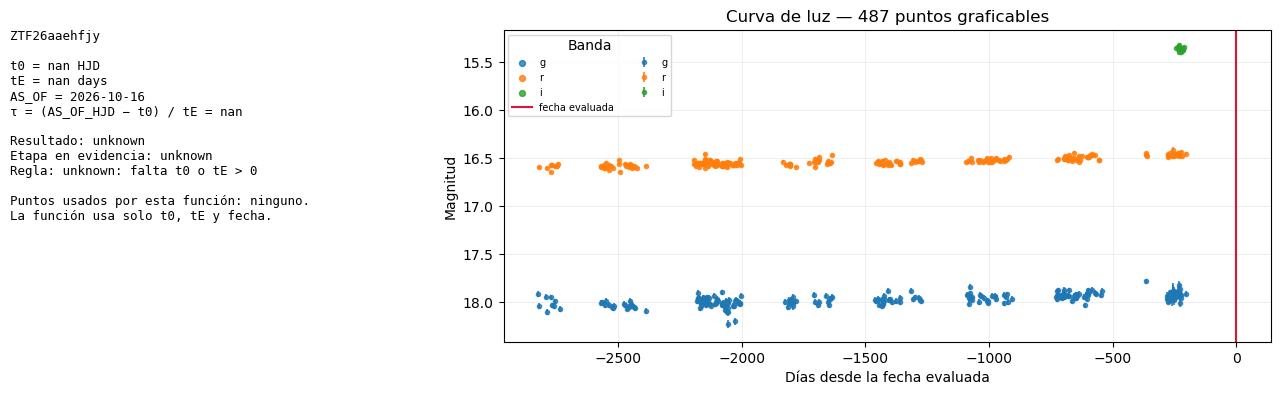

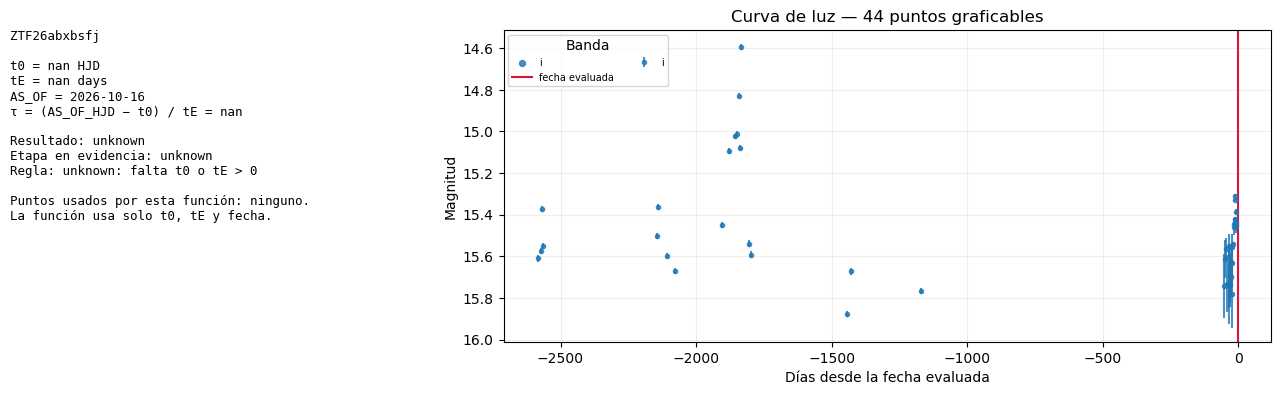

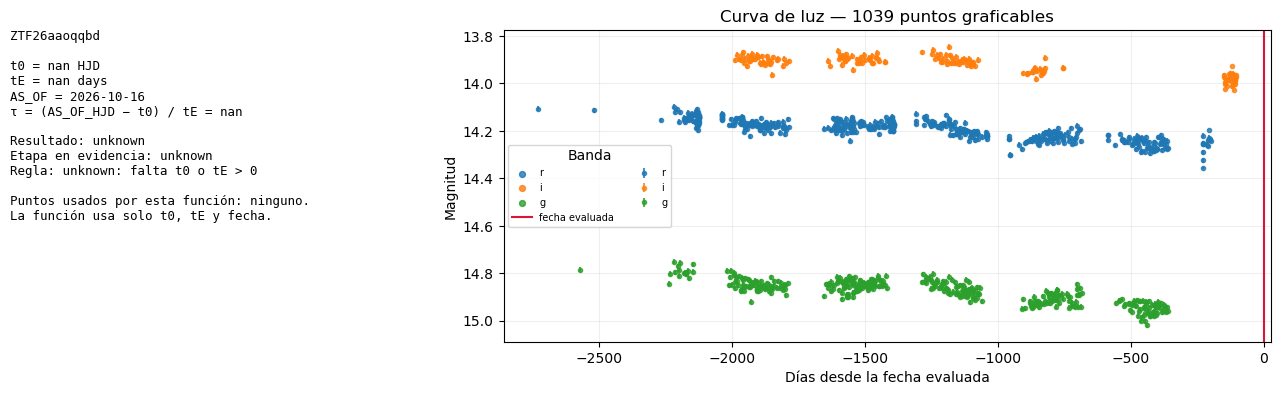

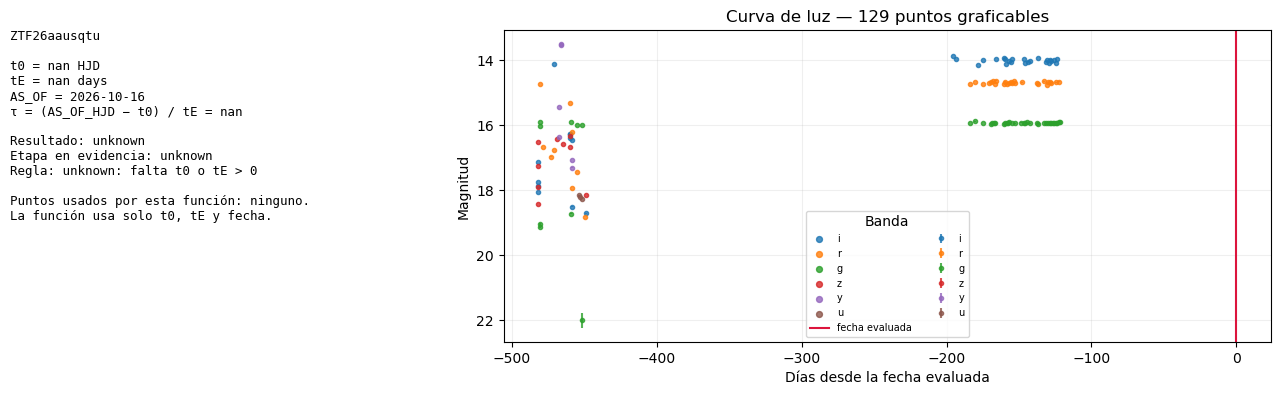

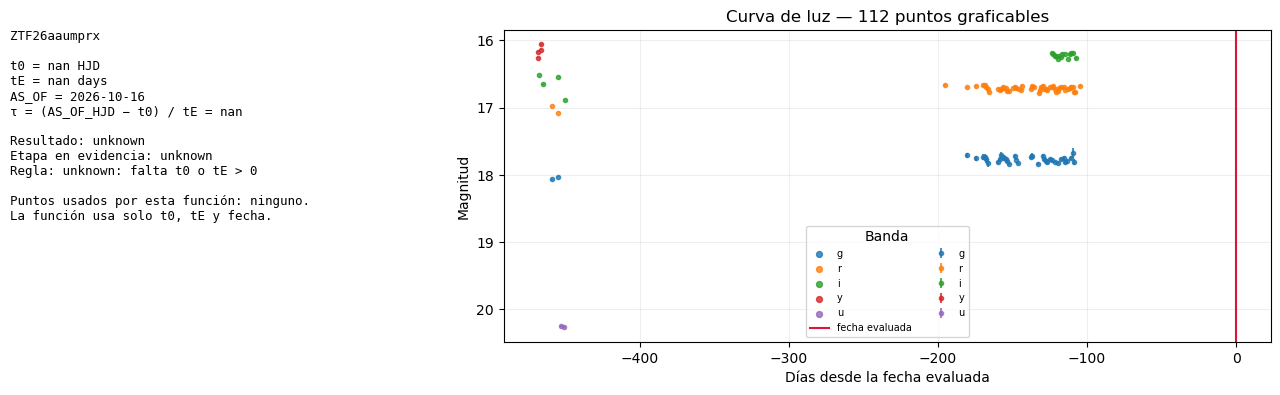

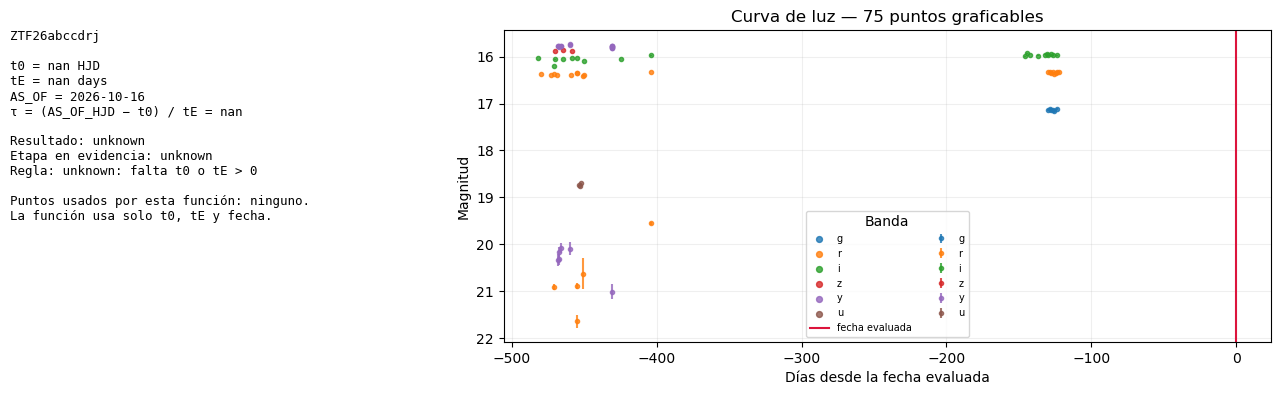

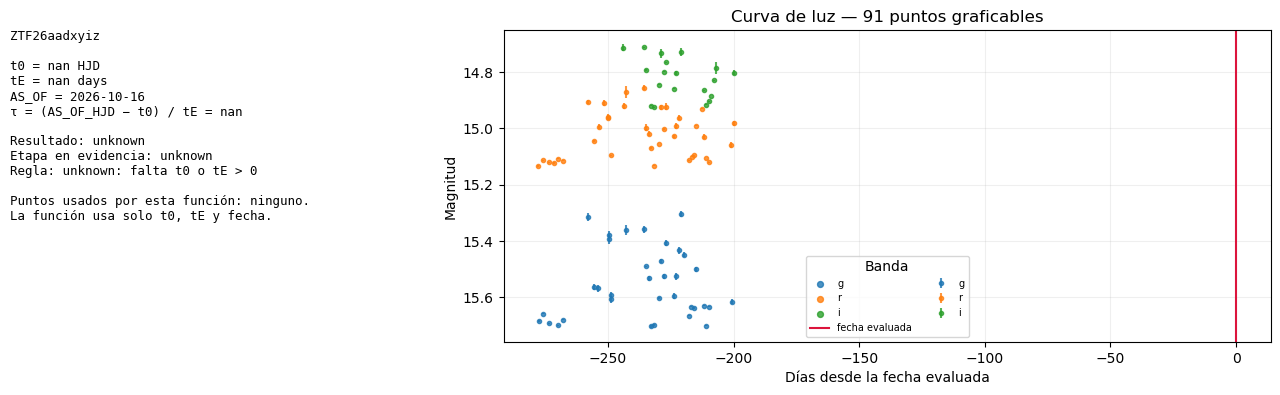

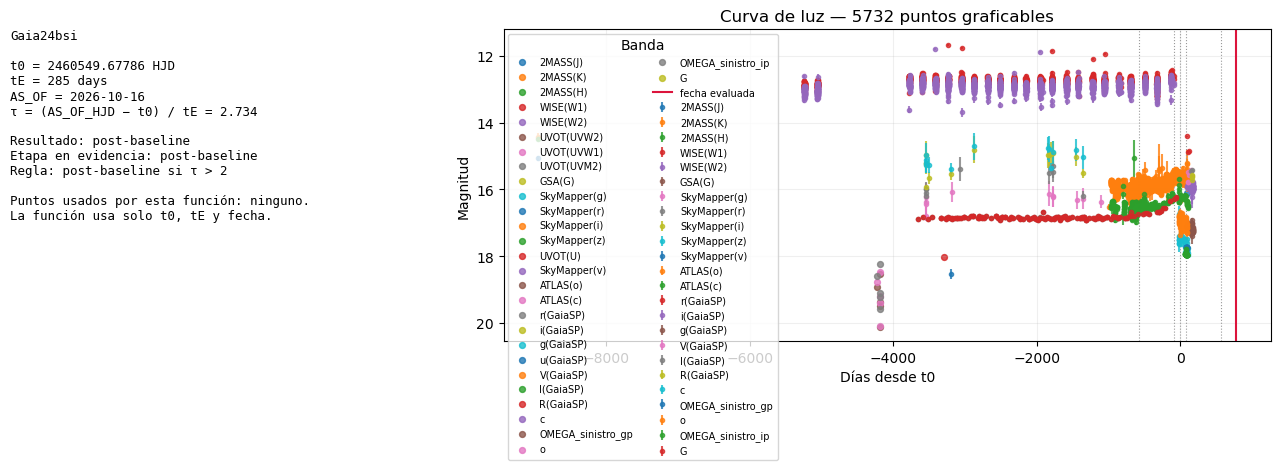

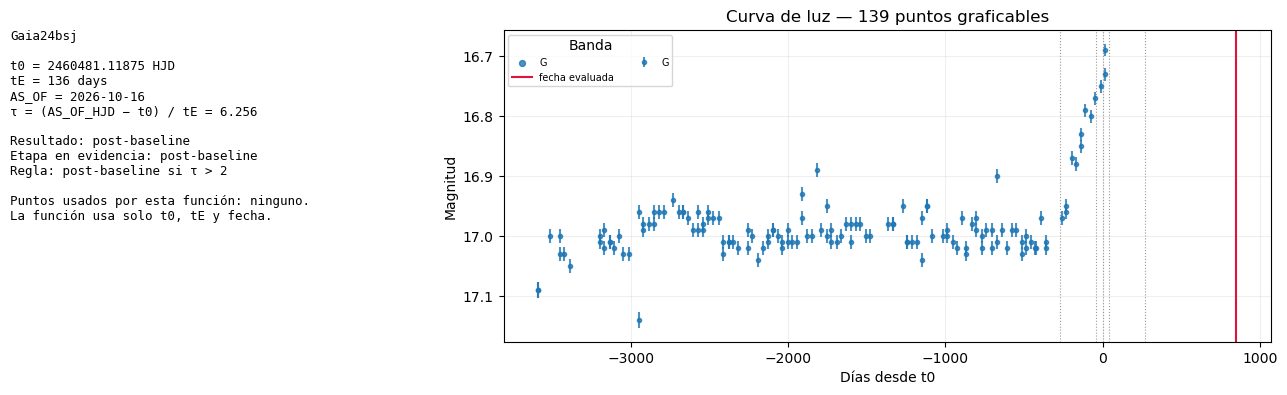

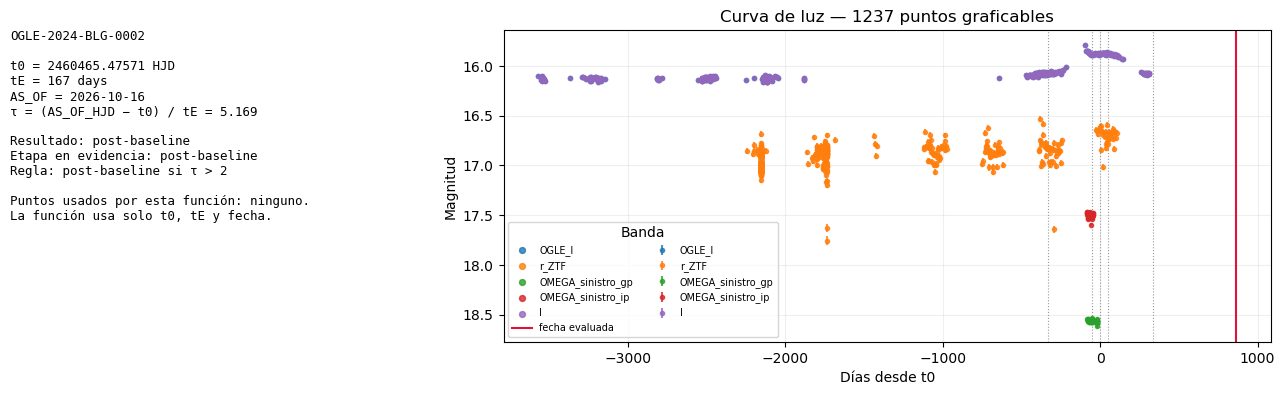

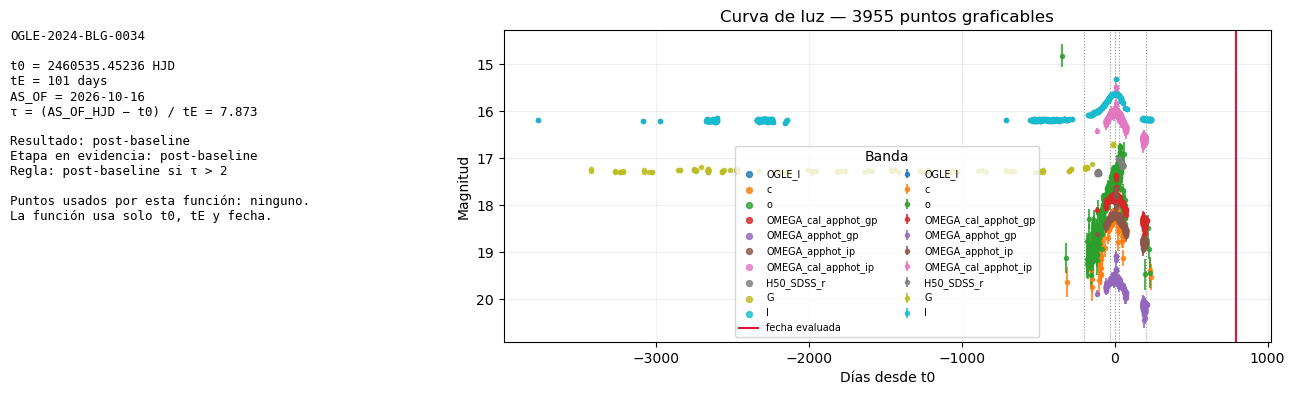

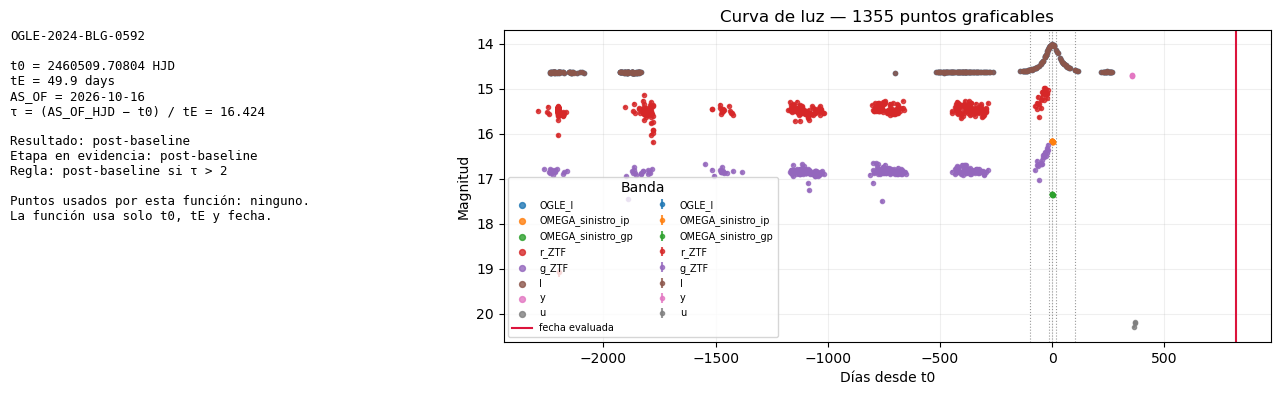

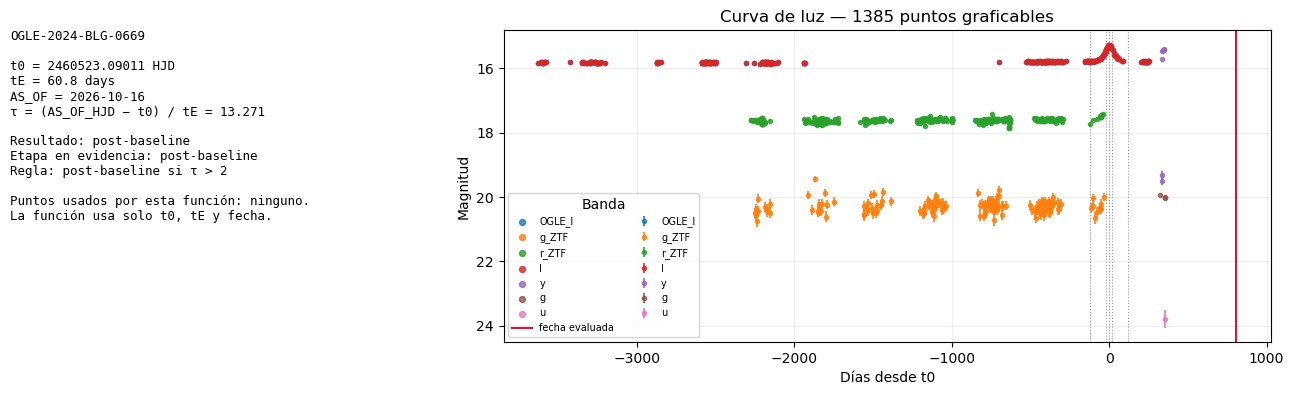

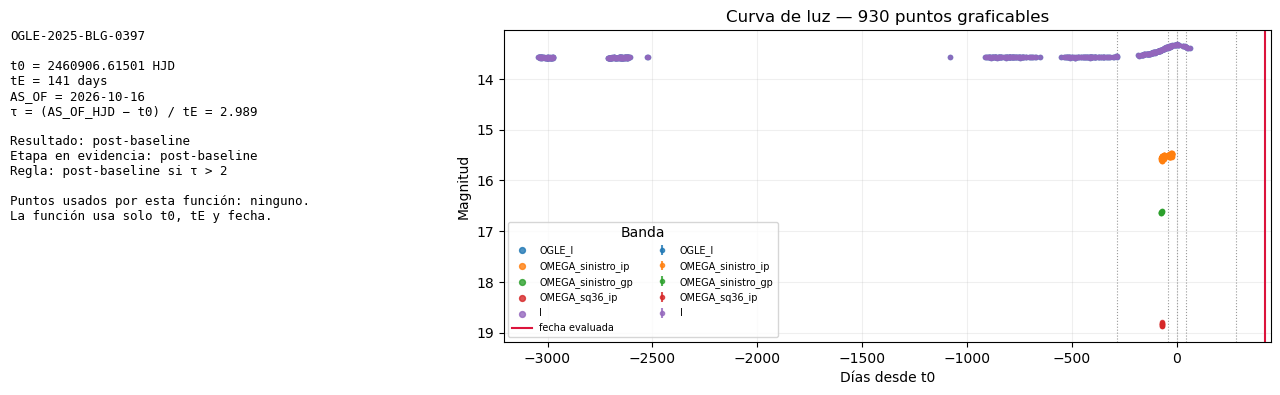

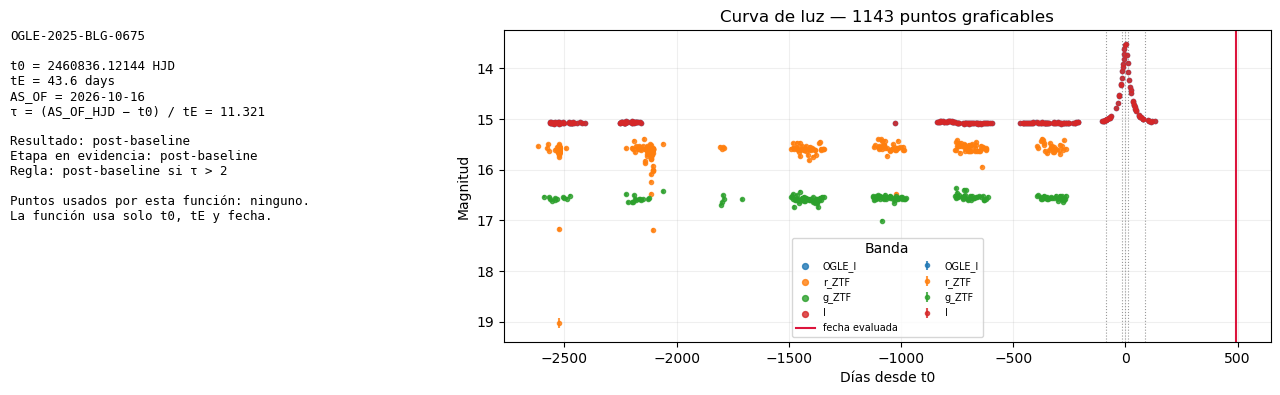

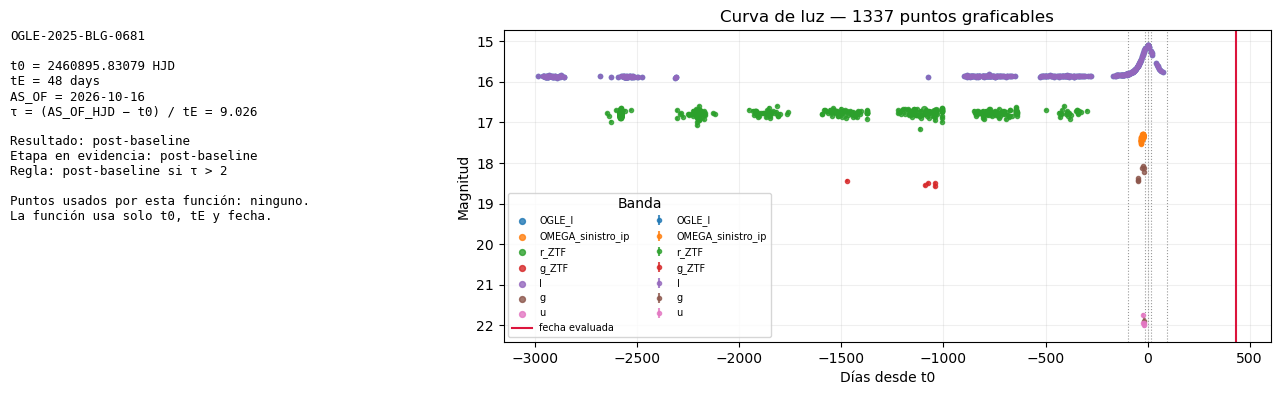

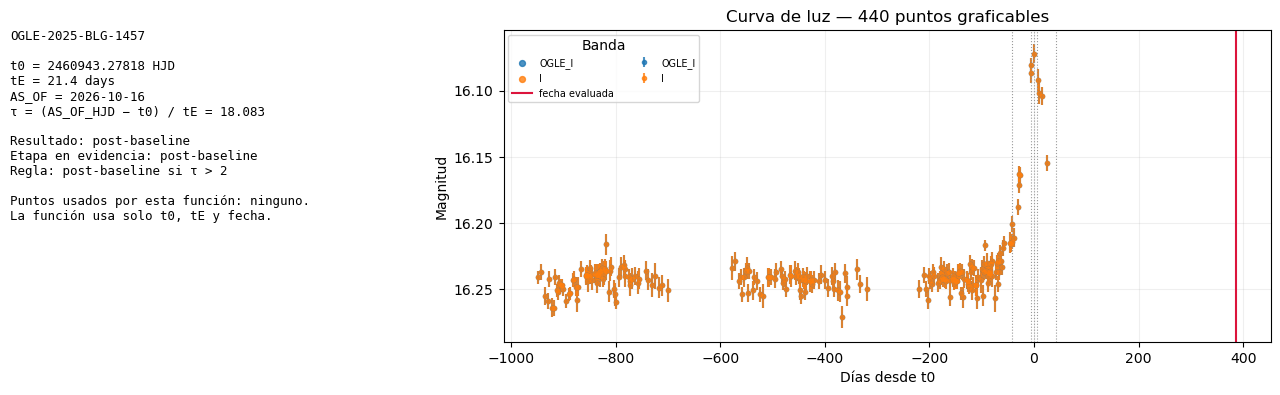

In [2]:
# La fecha se expresa en HJD para usar la misma escala que t0.
AS_OF_HJD = _as_hjd(AS_OF)
STAGE_NAMES = {
    'pre_baseline': 'pre-baseline', 'rise': 'rise', 'peak': 'peak',
    'decline': 'decline', 'post_baseline': 'post-baseline', 'unknown': 'unknown',
}

# Preparar puntos graficables con los mismos alias de época y magnitud que el módulo.
curve_data = observations.copy()
curve_data['_hjd'] = _epoch_hjd(curve_data)
curve_data['_mag'] = _coalesced_numeric(curve_data, ('magnitude', 'Magnitude', 'mag'))
curve_data['_err'] = _coalesced_numeric(curve_data, ('magnitude_err', 'Magnitude Error', 'magnitude_error', 'Error'))
curve_data['_band'] = _coalesced_text(curve_data, ('band', 'Filter', 'filter'), 'unknown')
curve_data = curve_data.loc[curve_data['_hjd'].notna() & curve_data['_mag'].notna()]

stage_rows = []
for _, target in evidence.iterrows():
    stage, tau = classify_event_stage(
        target['t0_hjd'], target['tE_days'], AS_OF_HJD, PRIORITY_CONFIG,
    )
    stage_rows.append({
        'target_id': target['target_id'], 't0_hjd': target['t0_hjd'],
        'tE_days': target['tE_days'], 'tau': tau,
        'stage_from_function': STAGE_NAMES[stage],
        'stage_in_evidence': STAGE_NAMES[target['event_stage']],
        'agrees_with_evidence': STAGE_NAMES[stage] == STAGE_NAMES[target['event_stage']],
    })
stage_review = pd.DataFrame(stage_rows)
display(stage_review)

for _, result in stage_review.iterrows():
    target_id = result['target_id']
    t0, tE, tau = result['t0_hjd'], result['tE_days'], result['tau']
    points = curve_data.loc[curve_data['target_id'].astype(str).eq(str(target_id))]
    fig, (logic_ax, curve_ax) = plt.subplots(
        1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [1.1, 2]},
    )
    logic_ax.axis('off')
    if pd.isna(tau):
        decision = 'unknown: falta t0 o tE > 0'
    elif tau < -PRIORITY_CONFIG.event_half_width_t_e:
        decision = f"pre-baseline si τ < −{PRIORITY_CONFIG.event_half_width_t_e:g}"
    elif tau < -PRIORITY_CONFIG.peak_half_width_t_e:
        decision = f"rise si −{PRIORITY_CONFIG.event_half_width_t_e:g} ≤ τ < −{PRIORITY_CONFIG.peak_half_width_t_e:g}"
    elif tau <= PRIORITY_CONFIG.peak_half_width_t_e:
        decision = f"peak si |τ| ≤ {PRIORITY_CONFIG.peak_half_width_t_e:g}"
    elif tau <= PRIORITY_CONFIG.event_half_width_t_e:
        decision = f"decline si {PRIORITY_CONFIG.peak_half_width_t_e:g} < τ ≤ {PRIORITY_CONFIG.event_half_width_t_e:g}"
    else:
        decision = f"post-baseline si τ > {PRIORITY_CONFIG.event_half_width_t_e:g}"
    logic_ax.text(
        0, 1, f"{target_id}\n\n"
        f"t0 = {t0:.5f} HJD\ntE = {tE:.3g} days\n"
        f"AS_OF = {AS_OF}\nτ = (AS_OF_HJD − t0) / tE = {tau:.3f}\n\n"
        f"Resultado: {result['stage_from_function']}\n"
        f"Etapa en evidencia: {result['stage_in_evidence']}\n"
        f"Regla: {decision}\n\n"
        "Puntos usados por esta función: ninguno.\n"
        "La función usa solo t0, tE y fecha.",
        va='top', ha='left', fontsize=9, family='monospace',
    )
    if not points.empty:
        x = points['_hjd'] - t0 if pd.notna(t0) else points['_hjd'] - AS_OF_HJD
        for band, band_points in points.assign(_x=x).groupby('_band', sort=False):
            valid_error = band_points['_err'].gt(0)
            if valid_error.any():
                curve_ax.errorbar(
                    band_points.loc[valid_error, '_x'], band_points.loc[valid_error, '_mag'],
                    yerr=band_points.loc[valid_error, '_err'], fmt='o', ms=3, capsize=0,
                    label=str(band), alpha=0.8,
                )
            curve_ax.scatter(
                band_points.loc[~valid_error, '_x'], band_points.loc[~valid_error, '_mag'],
                s=18, label=str(band), alpha=0.8,
            )
        curve_ax.invert_yaxis()
        if pd.notna(t0) and pd.notna(tE) and tE > 0:
            boundaries = [-PRIORITY_CONFIG.event_half_width_t_e, -PRIORITY_CONFIG.peak_half_width_t_e,
                          0, PRIORITY_CONFIG.peak_half_width_t_e, PRIORITY_CONFIG.event_half_width_t_e]
            for boundary in boundaries:
                curve_ax.axvline(boundary * tE, color='0.6', lw=0.8, ls=':')
            curve_ax.axvline(AS_OF_HJD - t0, color='crimson', lw=1.5, label='fecha evaluada')
            curve_ax.set_xlabel('Días desde t0')
        else:
            curve_ax.axvline(0, color='crimson', lw=1.5, label='fecha evaluada')
            curve_ax.set_xlabel('Días desde la fecha evaluada')
        curve_ax.set_ylabel('Magnitud')
        curve_ax.set_title(f"Curva de luz — {len(points)} puntos graficables")
        curve_ax.legend(title='Banda', fontsize=7, ncol=2)
        curve_ax.grid(alpha=0.2)
    else:
        curve_ax.text(0.5, 0.5, 'Sin puntos fotométricos ploteables', ha='center', va='center')
        curve_ax.set_axis_off()
    fig.subplots_adjust(left=0.02, right=0.99, top=0.94, bottom=0.12, wspace=0.12)
    display(fig)
    plt.close(fig)


In [ ]:
# Criterio: criterion_ended_event — Descarta eventos cuyo estado indica explícitamente que ya terminaron.
USE_EVENTO_TERMINADO = True  # Descarta eventos cuyo estado indica explícitamente que ya terminaron.
decisions = [
    criterion_ended_event(row, row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_ended_event', USE_EVENTO_TERMINADO, decisions, ['event_state', 'event_status', 'status'])

In [ ]:
# Criterio: criterion_supported_event — Pide etiqueta de microlensing, parámetros t0/tE o una subida que supere los umbrales.
USE_EVIDENCIA_DE_EVENTO = True  # Pide etiqueta de microlensing, parámetros t0/tE o una subida que supere los umbrales.
decisions = [
    criterion_supported_event(row, row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_supported_event', USE_EVIDENCIA_DE_EVENTO, decisions, ['event_type', 'classification', 'object_class', 'class', 'survey', 'event_class', 't0_hjd', 'tE_days', 'rise_significance_sigma', 'rise_points'])

In [ ]:
# Criterio: criterion_post_baseline — Descarta baseline posterior, salvo que exista una pregunta observacional explícita.
USE_BASELINE_POSTERIOR = True  # Descarta baseline posterior, salvo que exista una pregunta observacional explícita.
decisions = [
    criterion_post_baseline(row, row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_post_baseline', USE_BASELINE_POSTERIOR, decisions, ['event_stage', 'tau_tE', 'days_to_peak', 'planning_question', 'observation_question', 'priority_question'])

In [ ]:
# Criterio: criterion_casleo_continuity — Prioriza una visita CASLEO si falta una fase o el cambio esperado supera el detectable.
USE_CONTINUIDAD_CASLEO = True  # Prioriza una visita CASLEO si falta una fase o el cambio esperado supera el detectable.
decisions = [
    criterion_casleo_continuity(row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_casleo_continuity', USE_CONTINUIDAD_CASLEO, decisions, ['event_stage', 'n_casleo_observations', 'casleo_phases', 'expected_delta_mag', 'detectable_delta_mag'])

In [ ]:
# Criterio: criterion_casleo_stale_photometry — Marca para diagnóstico eventos seguidos por CASLEO con fotometría externa caduca.
USE_FOTOMETRIA_CADUCA_CASLEO = True  # Marca para diagnóstico eventos seguidos por CASLEO con fotometría externa caduca.
decisions = [
    criterion_casleo_stale_photometry(row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_casleo_stale_photometry', USE_FOTOMETRIA_CADUCA_CASLEO, decisions, ['n_casleo_observations', 'last_external_survey', 'days_since_external_photometry', 'external_stale_threshold_days', 'stale_external_data'])

In [ ]:
# Criterio: criterion_casleo_missing_uncertainty — Pide revisión si hay fase activa observada por CASLEO, pero no hay error para medir el cambio.
USE_INCERTIDUMBRE_CASLEO = True  # Pide revisión si hay fase activa observada por CASLEO, pero no hay error para medir el cambio.
decisions = [
    criterion_casleo_missing_uncertainty(row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_casleo_missing_uncertainty', USE_INCERTIDUMBRE_CASLEO, decisions, ['event_stage', 'n_casleo_observations', 'detectable_delta_mag'])

In [ ]:
# Criterio: criterion_casleo_observing_question — Conserva como oportunista un target CASLEO con una pregunta de observación pendiente.
USE_PREGUNTA_OBSERVACIONAL_CASLEO = True  # Conserva como oportunista un target CASLEO con una pregunta de observación pendiente.
decisions = [
    criterion_casleo_observing_question(row, row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_casleo_observing_question', USE_PREGUNTA_OBSERVACIONAL_CASLEO, decisions, ['n_casleo_observations', 'planning_question', 'observation_question', 'priority_question'])

In [ ]:
# Criterio: criterion_casleo_no_added_information — Descarta la continuidad CASLEO si no agrega una fase ni un cambio medible.
USE_SIN_INFORMACION_NUEVA_CASLEO = True  # Descarta la continuidad CASLEO si no agrega una fase ni un cambio medible.
decisions = [
    criterion_casleo_no_added_information(row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_casleo_no_added_information', USE_SIN_INFORMACION_NUEVA_CASLEO, decisions, ['n_casleo_observations', 'event_stage', 'casleo_phases', 'expected_delta_mag', 'detectable_delta_mag'])

In [ ]:
# Criterio: criterion_rising_event — Clasifica la subida con significancia mínima y cantidad mínima de puntos configurables.
USE_EVENTO_EN_SUBIDA = True  # Clasifica la subida con significancia mínima y cantidad mínima de puntos configurables.
decisions = [
    criterion_rising_event(row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_rising_event', USE_EVENTO_EN_SUBIDA, decisions, ['event_stage', 'rise_significance_sigma', 'rise_points'])

In [ ]:
# Criterio: criterion_peak_event — Identifica eventos dentro de la ventana de pico definida en unidades de tE.
USE_EVENTO_EN_PICO = True  # Identifica eventos dentro de la ventana de pico definida en unidades de tE.
decisions = [
    criterion_peak_event(row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_peak_event', USE_EVENTO_EN_PICO, decisions, ['event_stage', 'tau_tE', 'tE_days'])

In [ ]:
# Criterio: criterion_stale_photometry — Asigna diagnóstico a eventos no observados por CASLEO, fuera de subida/pico, con datos externos caducos.
USE_FOTOMETRIA_CADUCA_SIN_CASLEO = True  # Asigna diagnóstico a eventos no observados por CASLEO, fuera de subida/pico, con datos externos caducos.
decisions = [
    criterion_stale_photometry(row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_stale_photometry', USE_FOTOMETRIA_CADUCA_SIN_CASLEO, decisions, ['event_stage', 'n_casleo_observations', 'last_external_survey', 'days_since_external_photometry', 'external_stale_threshold_days', 'stale_external_data'])

In [ ]:
# Criterio: criterion_declining_event — Mantiene la bajada como oportunidad de menor prioridad; incorpora la pregunta observacional si existe.
USE_EVENTO_EN_BAJADA = True  # Mantiene la bajada como oportunidad de menor prioridad; incorpora la pregunta observacional si existe.
decisions = [
    criterion_declining_event(row, row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_declining_event', USE_EVENTO_EN_BAJADA, decisions, ['event_stage', 'n_casleo_observations', 'planning_question', 'observation_question', 'priority_question'])

In [ ]:
# Criterio: criterion_unknown_event_stage — Pide revisión cuando faltan t0/tE para ubicar la fase del evento.
USE_ETAPA_DESCONOCIDA = True  # Pide revisión cuando faltan t0/tE para ubicar la fase del evento.
decisions = [
    criterion_unknown_event_stage(row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_unknown_event_stage', USE_ETAPA_DESCONOCIDA, decisions, ['event_stage', 't0_hjd', 'tE_days', 'tau_tE'])

In [ ]:
# Criterio: criterion_fallback — Asigna REVISAR cuando ningún criterio anterior define una categoría.
USE_SIN_REGLA_APLICABLE = True  # Asigna REVISAR cuando ningún criterio anterior define una categoría.
decisions = [
    criterion_fallback(row.to_dict(), PRIORITY_CONFIG)
    for _, row in evidence.iterrows()
]
show_criterion('criterion_fallback', USE_SIN_REGLA_APLICABLE, decisions, ['event_stage', 'n_photometry', 'rise_significance_sigma', 'stale_external_data'])

## Implementación vigente, sin interruptores

Esta sección vuelve a ejecutar `evaluate_priority` con los mismos inputs y umbrales. La categoría/razón de la columna `current_...` es el resultado real del módulo; se muestran todos los targets para que los excluidos por falta de fotometría queden visibles como tales.

In [ ]:
current = evaluate_priority(
    targets, observations, visibility, as_of=AS_OF, config=PRIORITY_CONFIG,
)
current = current[['target_id', 'priority_category', 'priority_reason']].rename(columns={
    'priority_category': 'current_category', 'priority_reason': 'current_reason',
})
comparison = evidence.merge(experiment, on='target_id', how='left').merge(current, on='target_id', how='left')
comparison_columns = [
    'target_id', 'n_photometry', 'event_stage', 'rise_significance_sigma', 'rise_points',
    'stale_external_data', 'days_since_external_photometry', 'n_casleo_observations',
    'priority_category', 'priority_reason', 'current_category', 'current_reason',
]
display(comparison.reindex(columns=comparison_columns).sort_values('target_id').reset_index(drop=True))